Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Training/
Testing/
Device: cpu
Loading training data...
Loading test data...
Mean: [0.17806078 0.1780633  0.17809008], Std: [0.18898967 0.1889886  0.18902448]
Training SimpleCNN
[SimpleCNN] Ep 01/10 | train loss 2.6360 acc 0.5681 | val loss 0.8006 acc 0.6950 | lr 1.00e-03 | 95.2s
[SimpleCNN] Ep 02/10 | train loss 0.8135 acc 0.6831 | val loss 0.7145 acc 0.6750 | lr 1.00e-03 | 96.6s
[SimpleCNN] Ep 03/10 | train loss 0.7383 acc 0.6919 | val loss 0.5715 acc 0.7825 | lr 1.00e-03 | 96.4s
[SimpleCNN] Ep 04/10 | train loss 0.7273 acc 0.7081 | val loss 0.5934 acc 0.7425 | lr 1.00e-03 | 98.2s
[SimpleCNN] Ep 05/10 | train loss 0.6528 acc 0.7400 | val loss 0.5262 acc 0.8050 | lr 1.00e-03 | 97.0s
[SimpleCNN] Ep 06/10 | train loss 0.6461 acc 0.7462 | val loss 0.5077 acc 0.8000 | lr 1.00e-03 | 98.9s
[SimpleCNN] Ep 07/10 | train loss 0.6015 acc 0.7594 | val loss 0.5316 acc 0.8200 | lr 1.00e-03 | 97.0s
[SimpleCNN] Ep 08/10 | 

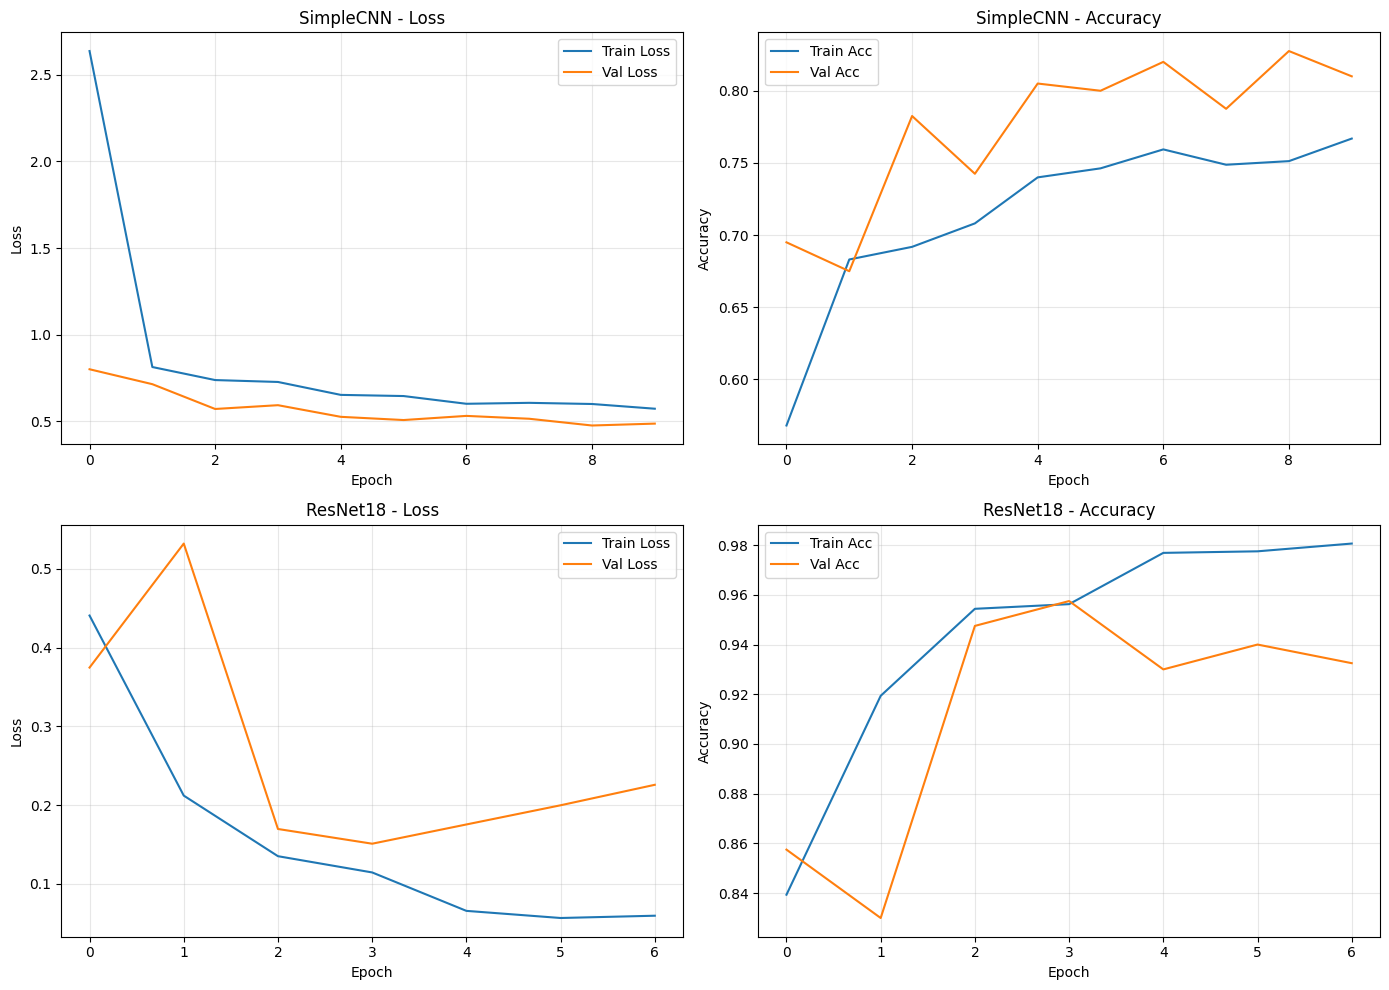

SimpleCNN — Test Accuracy: 0.7475
              precision    recall  f1-score   support

      glioma     0.7738    0.6500    0.7065       100
  meningioma     0.7000    0.4200    0.5250       100
     notumor     0.7520    0.9400    0.8356       100
   pituitary     0.7481    0.9800    0.8485       100

    accuracy                         0.7475       400
   macro avg     0.7435    0.7475    0.7289       400
weighted avg     0.7435    0.7475    0.7289       400



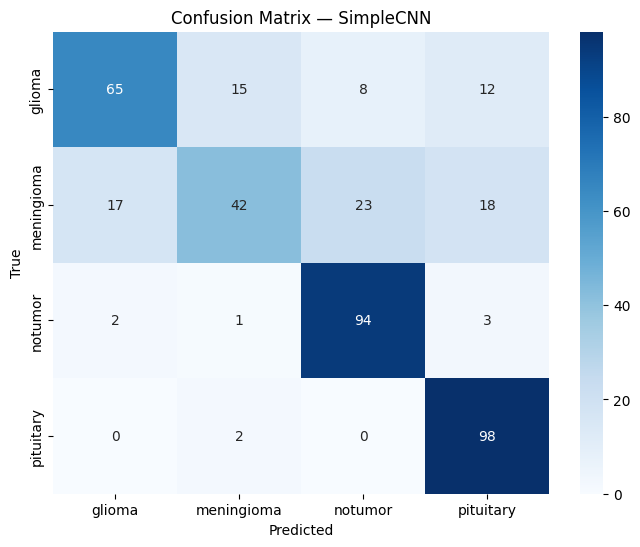

ResNet18 — Test Accuracy: 0.8950
              precision    recall  f1-score   support

      glioma     0.9873    0.7800    0.8715       100
  meningioma     0.8000    0.8800    0.8381       100
     notumor     0.9048    0.9500    0.9268       100
   pituitary     0.9151    0.9700    0.9417       100

    accuracy                         0.8950       400
   macro avg     0.9018    0.8950    0.8945       400
weighted avg     0.9018    0.8950    0.8945       400



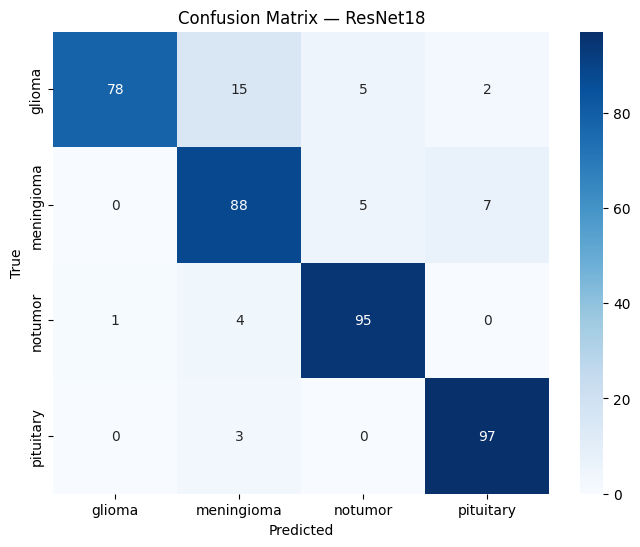

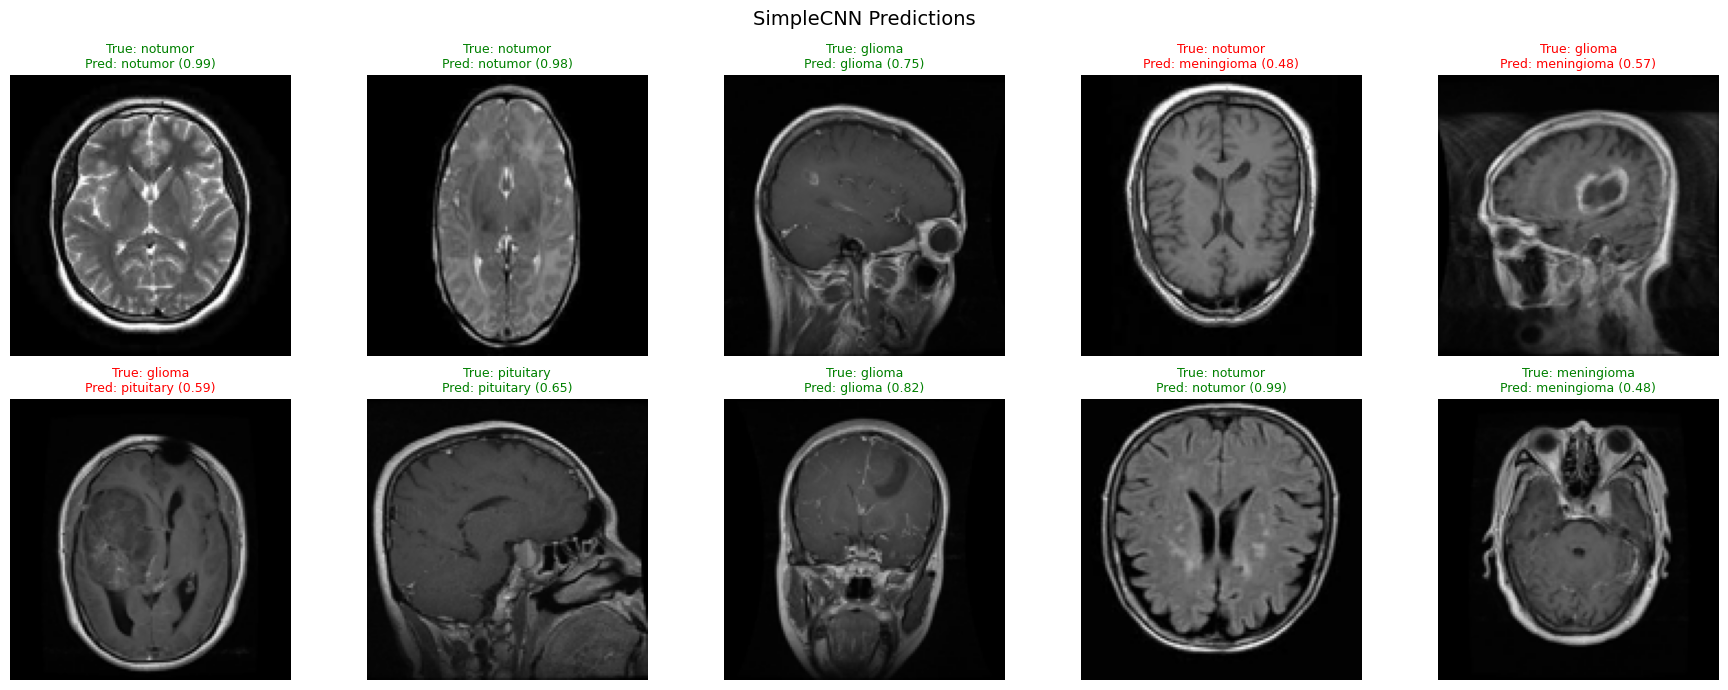

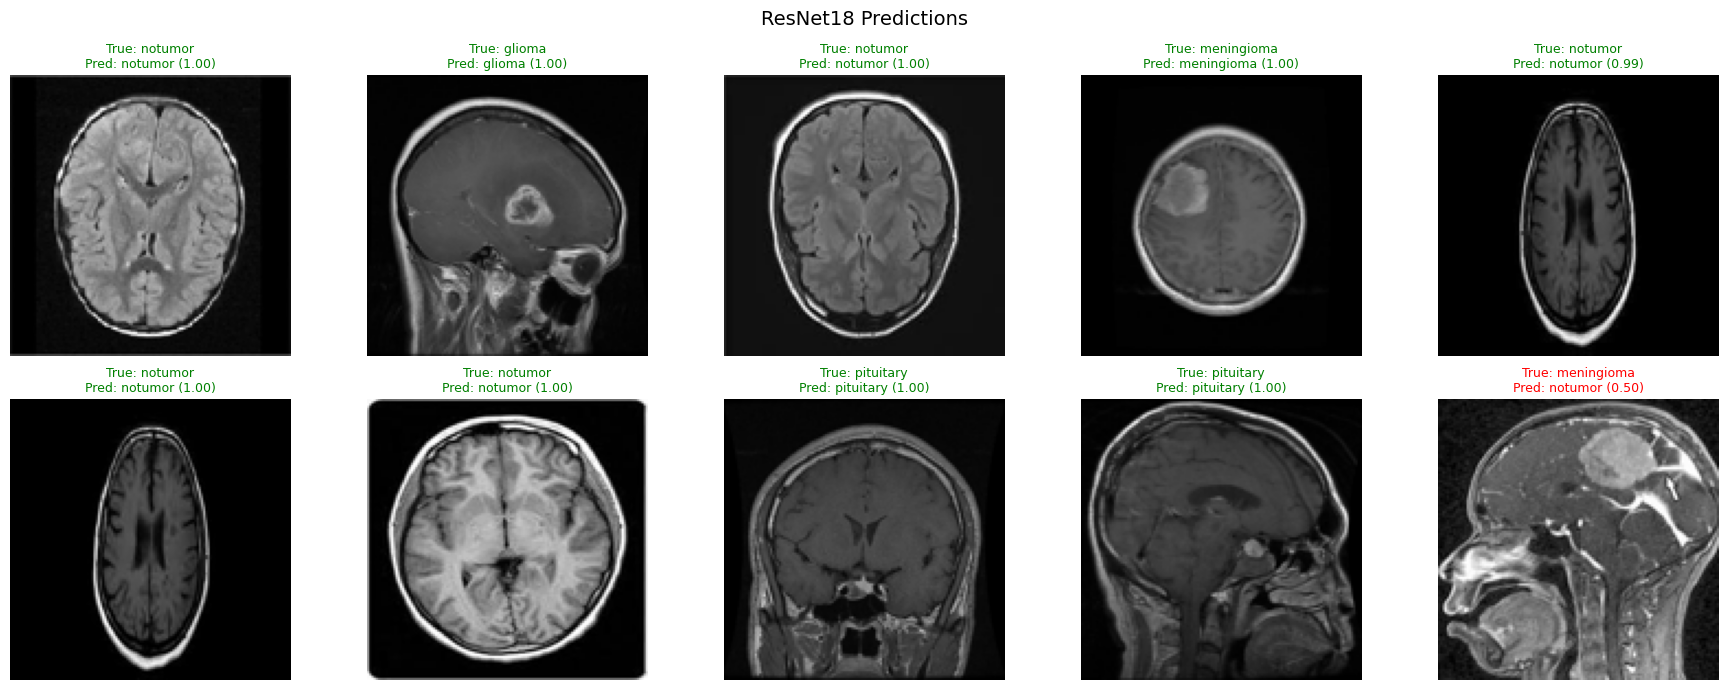

Сводная таблица результатов


,Params,Best val acc,Test acc,Mean epoch time (s),Epochs trained
Model,,,,,
SimpleCNN,"8,483,588",0.8275,0.7475,97.1,10
ResNet18,"11,178,564",0.9575,0.8950,163.6,7


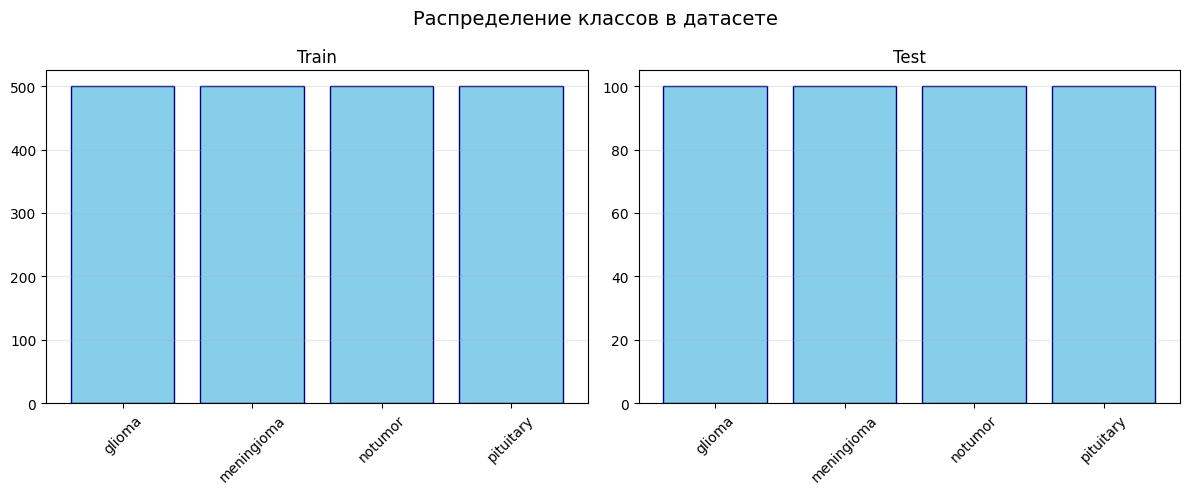

In [4]:
!pip install kagglehub torch torchvision --quiet

import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

#Загрузка датасета
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

#Исследование структуры данных
#Проверка структуру папок
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level < 2:
        indent = " " * level
        if level < 1:
            for d in dirs:
                print(f"{indent}{d}/")

#Подготовка данных
IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

#Фиксация случайных сидов
np.random.seed(SEED)
torch.manual_seed(SEED)

#Определение устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

#Пути к данным
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR = os.path.join(path, "Testing")

#Получение списка классов
classes = sorted(os.listdir(TRAIN_DIR))
num_classes = len(classes)

#Функция загрузки данных
def load_dataset(root_dir, classes, img_size=128, max_per_class=None):
    images = []
    labels = []

    for cls_idx, cls in enumerate(classes):
        cls_path = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        files = os.listdir(cls_path)
        files = files[:max_per_class]
        for filename in files:
            img_path = os.path.join(cls_path, filename)
            img = Image.open(img_path).convert("RGB")
            img = img.resize((img_size, img_size))
            images.append(np.array(img))
            labels.append(cls_idx)
    return np.array(images, dtype=np.uint8), np.array(labels)

#Загрузка тренировочных данных
print("Loading training data...")
X_train_all, y_train_all = load_dataset(TRAIN_DIR, classes, IMG_SIZE, max_per_class=500)

#Загружаем тестовых данных
print("Loading test data...")
X_test, y_test = load_dataset(TEST_DIR, classes, IMG_SIZE, max_per_class=100)

#Разделение на train/val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_all
)

#Аугментация данных и нормализация
#Вычисление mean и std для нормализации
X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2))
std = X_train_f.std(axis=(0, 1, 2))
print(f"Mean: {mean}, Std: {std}")

#Трансформации для тренировки
train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

#Трансформации для валидации и теста
eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

#Dataset
class BrainTumorDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

#DataLoaders
train_dataset = BrainTumorDataset(X_train, y_train, train_tfms)
val_dataset = BrainTumorDataset(X_val, y_val, eval_tfms)
test_dataset = BrainTumorDataset(X_test, y_test, eval_tfms)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


#CNN
class SimpleBrainTumorCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(128 * (IMG_SIZE // 8) * (IMG_SIZE // 8), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

#RESNET18
def create_resnet18(num_classes=4, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    #Замена последнего слоя
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

#Функции для обучения
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    y_true = []
    y_pred = []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        outputs = model(xb)
        loss = criterion(outputs, yb)
        running_loss += loss.item() * xb.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=10, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2
    )
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'time': []
    }

    best_val_acc = 0.0
    patience_counter = 0
    print(f"Training {title}")

    for epoch in range(epochs):
        import time
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "time"],
                       [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)
        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | "
              f"{dt:.1f}s")

        #Early stopping
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
    return history

#Функция для полного отчета
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = evaluate(model, loader, criterion)
    print(f"{title} — Test Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred,
                                target_names=classes,
                                digits=4))

    #Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

#Обучение моделей
#Обучение CNN
cnn_model = SimpleBrainTumorCNN(num_classes=num_classes).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=10, lr=1e-3, weight_decay=1e-5,
               patience=5, title="SimpleCNN")

#Обучение ResNet18
resnet_model = create_resnet18(num_classes=num_classes, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")


#Визуализация
#Графики обучения CNN
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
#Loss
axes[0, 0].plot(hist_cnn['train_loss'], label='Train Loss')
axes[0, 0].plot(hist_cnn['val_loss'], label='Val Loss')
axes[0, 0].set_title('SimpleCNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

#Accuracy
axes[0, 1].plot(hist_cnn['train_acc'], label='Train Acc')
axes[0, 1].plot(hist_cnn['val_acc'], label='Val Acc')
axes[0, 1].set_title('SimpleCNN - Accuracy')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

#Графики обучения ResNet
#Loss
axes[1, 0].plot(hist_resnet['train_loss'], label='Train Loss')
axes[1, 0].plot(hist_resnet['val_loss'], label='Val Loss')
axes[1, 0].set_title('ResNet18 - Loss')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

#Accuracy
axes[1, 1].plot(hist_resnet['train_acc'], label='Train Acc')
axes[1, 1].plot(hist_resnet['val_acc'], label='Val Acc')
axes[1, 1].set_title('ResNet18 - Accuracy')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Тестовая производительность CNN
res_cnn = full_report(cnn_model, test_loader, "SimpleCNN")

#Тестовая производительность ResNet
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

#Примеры предсказаний CNN
@torch.no_grad()
def show_predictions(model, images, labels, n=10, title="Model"):
    model.eval()
    idxs = np.random.choice(len(images), n, replace=False)

    fig, axes = plt.subplots(2, n//2, figsize=(18, 7))

    for ax, i in zip(axes.ravel(), idxs):
        tensor = eval_tfms(images[i]).unsqueeze(0).to(device)
        outputs = model(tensor)
        prob = torch.softmax(outputs, dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))

        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"True: {classes[labels[i]]}\nPred: {classes[pred]} ({prob[pred]:.2f})",
                    color=color, fontsize=9)
        ax.axis('off')

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_predictions(cnn_model, X_test, y_test, n=10, title="SimpleCNN Predictions")
show_predictions(resnet_model, X_test, y_test, n=10, title="ResNet18 Predictions")

#Сводная таблица результатов
def summarize(name, hist, result, model):
    total_params = sum(p.numel() for p in model.parameters())
    return {
        "Model": name,
        "Params": f"{total_params:,}",
        "Best val acc": f"{max(hist['val_acc']):.4f}",
        "Test acc": f"{result['acc']:.4f}",
        "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
        "Epochs trained": len(hist["time"]),
    }
df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn, res_cnn, cnn_model),
    summarize("ResNet18", hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
print("Сводная таблица результатов")
display(df_cmp)

#Распределение классов
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    unique, counts = np.unique(y_, return_counts=True)
    class_names = [classes[i] for i in unique]
    ax.bar(class_names, counts, color='skyblue', edgecolor='navy')
    ax.set_title(ttl)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.3, axis='y')
plt.suptitle("Распределение классов в датасете", fontsize=14)
plt.tight_layout()
plt.show()